<a href="https://colab.research.google.com/github/ajaymenon336-tech/data-cleaning-project/blob/main/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Identification
* **Name: Ajay Menon**

* **Student ID: 12240283**
* **Group: A**
* **Chosen Dataset: Pima Indians Diabetes Dataset**
* **Algorithm:KNN**




# Loading Dataset

In [1]:
import pandas as pd

data = pd.read_csv("diabetes.csv")

data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


#Preprocessing

In [2]:
data.shape

(768, 9)

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
data.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [5]:
data.eq(0).sum()

,0
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


In [6]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print(zero_columns)
#some of these columns have zero values which represents missing values, we replace the zeroes with the median in the training data(to avoid data leakage)

['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']


In [7]:
data.duplicated().sum()

np.int64(0)

#Exploratory Data Plots

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

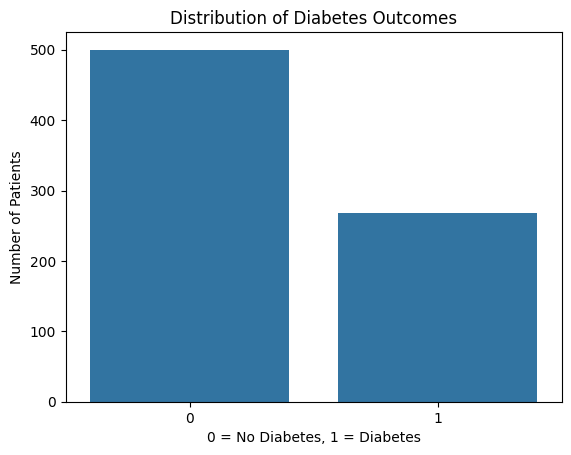

In [9]:
sns.countplot(data=data, x="Outcome")

plt.title("Distribution of Diabetes Outcomes")
plt.xlabel("0 = No Diabetes, 1 = Diabetes")
plt.ylabel("Number of Patients")

plt.show()

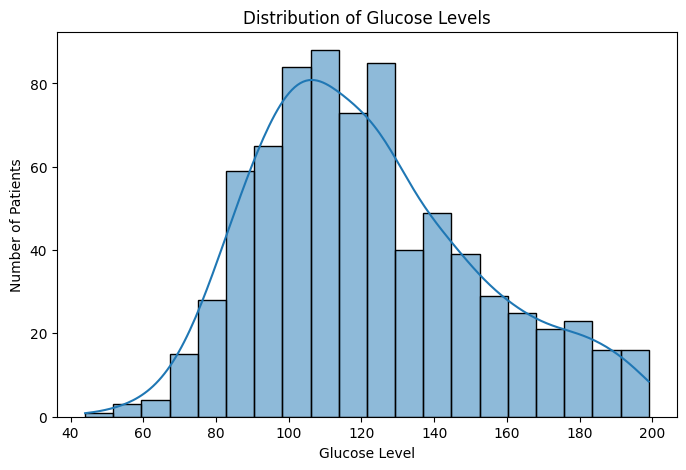

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data[data["Glucose"] != 0],
    x="Glucose",
    bins=20,
    kde=True
)

plt.title("Distribution of Glucose Levels")
plt.xlabel("Glucose Level")
plt.ylabel("Number of Patients")

plt.show()

# Dataset Splitting



In [11]:
x=data.drop("Outcome",axis=1)
y=data["Outcome"]


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [14]:
print(X_train.shape)


(614, 8)


In [15]:
print(X_test.shape)

(154, 8)


In [16]:
print(y_train.shape)

(614,)


In [17]:
print(y_test.shape)

(154,)


In [21]:
import numpy as np
from sklearn.impute import SimpleImputer

X_train[zero_columns] = X_train[zero_columns].replace(0, np.nan)
X_test[zero_columns] = X_test[zero_columns].replace(0, np.nan)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)

X_test = imputer.transform(X_test)

print(np.isnan(X_train).sum())
print( np.isnan(X_test).sum())

0
0


In [25]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit and scale training data
X_train = scaler.fit_transform(X_train)

# Scale testing data using training parameters
X_test = scaler.transform(X_test)

#Model Training

In [26]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

KNeighborsClassifier()

#Prediction

In [27]:
y_pred = knn.predict(X_test)

print(y_pred[:10])

[1 0 0 1 0 0 0 1 0 1]


#Results & Evaluation Plot

In [33]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, y_pred)

print(accuracy * 100, "%")


75.32467532467533 %


In [31]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



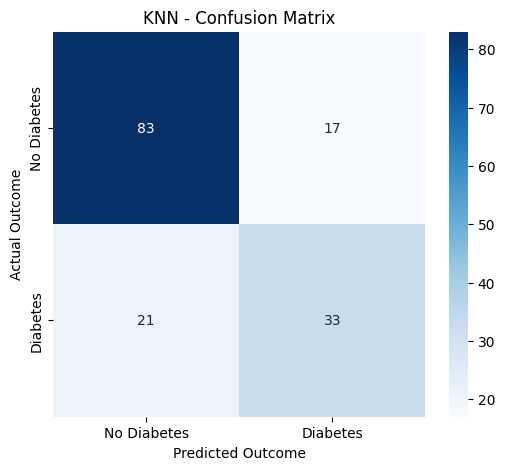

In [32]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.show()